# RANDOM FOREST - ENTROPY (100 POHON)

### Deskripsi Teori & Varian:
* **Algoritma**: Random Forest (Ensemble Learning)
* **Varian**: Entropy / Information Gain (100 Pohon)
* **Konsep**: Berbeda dengan Gini yang mengukur ketidakmurnian, kriteria **Entropy** mengukur tingkat "ketidakpastian" informasi. Pohon keputusan akan memilih pemisahan fitur yang paling banyak mengurangi Entropy (Information Gain). Varian ini diuji untuk melihat apakah pendekatan probabilistik ini lebih baik dari Gini pada data teks.

In [1]:
import time
import tracemalloc
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

df_hoaks = pd.read_csv('../data/komdigi_hoaks.csv')
df_valid = pd.read_csv('../web/uploads/berita_valid_terbaru.csv')

def clean_text(text):
    if not isinstance(text, str): return ''
    text = re.sub(r'\[(HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\]', '', text, flags=re.IGNORECASE)
    text = re.sub(r'\((HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\)', '', text, flags=re.IGNORECASE)
    text = re.sub(r'https?:\/\/\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    return re.sub(r'\s+', ' ', text.lower()).strip()

df_hoaks['teks_bersih'] = (df_hoaks['title'].fillna('') + ' ' + df_hoaks['excerpt'].fillna('')).apply(clean_text)
df_valid['teks_bersih'] = (df_valid['title'].fillna('') + ' ' + df_valid['excerpt'].fillna('')).apply(clean_text)

df_hoaks['label'] = 1
df_valid['label'] = 0

df_hoaks_sampel = df_hoaks.sample(n=len(df_valid), random_state=42)
df_all = pd.concat([df_hoaks_sampel, df_valid], ignore_index=True)
df_all = df_all[df_all['teks_bersih'].str.len() > 10].reset_index(drop=True)

X_train, X_test, y_train, y_test = train_test_split(
    df_all['teks_bersih'], df_all['label'], test_size=0.2, random_state=42, stratify=df_all['label']
)
tfidf = TfidfVectorizer(max_features=1500, ngram_range=(1, 2))
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

print("Preprocessing Selesai!")

Preprocessing Selesai!


In [2]:
tracemalloc.start()
waktu_mulai = time.time()

# Model Random Forest - Entropy (100 Pohon)
model = RandomForestClassifier(n_estimators=100, criterion='entropy', max_depth=None, random_state=42)
model.fit(X_train_vec, y_train)
y_pred = model.predict(X_test_vec)

waktu_eksekusi = time.time() - waktu_mulai
current_mem, peak_mem = tracemalloc.get_traced_memory()
tracemalloc.stop()
memori_mb = peak_mem / (1024 * 1024)

acc = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec_macro = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)
f1_weighted = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print("=============================================")
print("HASIL PENGUJIAN: RANDOM FOREST - ENTROPY (100 POHON)")
print("=============================================")
print(f"1. Algoritma        : Random Forest")
print(f"2. Metrik Jarak     : Entropy / Information Gain")
print(f"3. Akurasi          : {acc:.4f}")
print(f"4. Precision (Macro): {prec_macro:.4f}")
print(f"5. Recall (Macro)   : {rec_macro:.4f}")
print(f"6. F1-Score (Macro) : {f1_macro:.4f}")
print(f"7. F1-Score (Weighted): {f1_weighted:.4f}")
print(f"8. Waktu Eksekusi   : {waktu_eksekusi:.4f} detik")
print(f"9. Penggunaan Memori: {memori_mb:.2f} MB")
print("=============================================\n")

print("Laporan Klasifikasi Detail:")
print(classification_report(y_test, y_pred, target_names=['Valid (0)', 'Hoaks (1)'], zero_division=0))

HASIL PENGUJIAN: RANDOM FOREST - ENTROPY (100 POHON)
1. Algoritma        : Random Forest
2. Metrik Jarak     : Entropy / Information Gain
3. Akurasi          : 0.9133
4. Precision (Macro): 0.9181
5. Recall (Macro)   : 0.9133
6. F1-Score (Macro) : 0.9131
7. F1-Score (Weighted): 0.9131
8. Waktu Eksekusi   : 1.0604 detik
9. Penggunaan Memori: 0.40 MB

Laporan Klasifikasi Detail:
              precision    recall  f1-score   support

   Valid (0)       0.96      0.86      0.91       150
   Hoaks (1)       0.87      0.97      0.92       150

    accuracy                           0.91       300
   macro avg       0.92      0.91      0.91       300
weighted avg       0.92      0.91      0.91       300



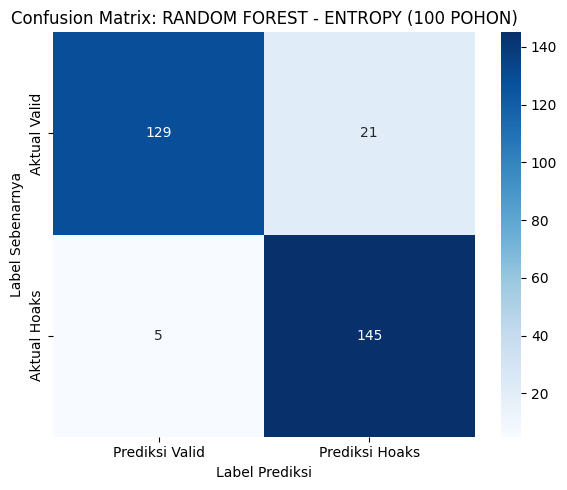

In [4]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Prediksi Valid', 'Prediksi Hoaks'],
            yticklabels=['Aktual Valid', 'Aktual Hoaks'])
plt.title('Confusion Matrix: RANDOM FOREST - ENTROPY (100 POHON)')
plt.ylabel('Label Sebenarnya')
plt.xlabel('Label Prediksi')
plt.tight_layout()
plt.show()

### Pembahasan Akademis: Random Forest (Entropy - 100 Pohon)

1. **Analisis Performa & Akurasi**:
   * Model Random Forest dengan kriteria Entropy menghasilkan akurasi sebesar **91.33%** dengan F1-Score 0.9131. Angka ini **sama persis** dengan performa kriteria Gini, membuktikan bahwa secara umum, Random Forest sangat stabil dan tangguh dalam mengklasifikasi teks hoaks, terlepas dari kriteria pemisahan yang digunakan.

2. **Perbedaan Karakteristik Confusion Matrix (Gini vs Entropy)**:
   * Meskipun akurasinya sama, ada perbedaan perilaku yang menarik:
     * **Gini** menebak 132 Valid benar dan 142 Hoaks benar (8 Hoaks lolos).
     * **Entropy** menebak 129 Valid benar dan **145 Hoaks benar** (hanya 5 Hoaks yang lolos).
   * Fakta bahwa Entropy hanya meloloskan 5 berita Hoaks membuktikan bahwa **Entropy (Information Gain) lebih agresif dalam mendeteksi pola kata-kata hoaks**. Entropy cenderung memilih pemisahan yang memaksimalkan informasi, sehingga lebih "waspada" terhadap kata-kata provokatif. Konsekuensinya, ia sedikit lebih banyak salah menebak berita Valid sebagai Hoaks (21 data).

3. **Trade-off Waktu**:
   * Waktu eksekusi mencapai **1.0604 detik**. Sedikit lebih lambat dibanding Gini (0.9907 detik). Hal ini wajar karena perhitungan logaritma pada rumus Entropy (\(-p \log_2 p\)) secara komputasi lebih berat dibanding perhitungan kuadrat sederhana pada Gini Impurity.